In [ ]:
!pip -q install cbor2

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving industrial_-fan-anomaly-detection-demo-(accelerometer)-export.zip to industrial_-fan-anomaly-detection-demo-(accelerometer)-export.zip


In [ ]:
import os, glob, zipfile

FOLDER = "/content/drive/MyDrive/Frontier day"
matches = glob.glob(os.path.join(FOLDER, "industrial*"))
print("Found:", matches)

src = matches[0]
EXTRACT = "/content/machine_data"

if zipfile.is_zipfile(src):
    with zipfile.ZipFile(src) as z:
        z.extractall(EXTRACT)
    base = EXTRACT
else:
    base = src          # already a folder

# find the folder that contains both training/ and testing/
DATA_ROOT = None
for root, dirs, _ in os.walk(base):
    if "training" in dirs and "testing" in dirs:
        DATA_ROOT = root
        break

print("DATA_ROOT:", DATA_ROOT)

# show what is inside
from collections import Counter
for split in ["training", "testing"]:
    names = os.listdir(os.path.join(DATA_ROOT, split))
    print(split, len(names), "files |",
          Counter(n.split(".")[0] for n in names),
          "| extensions:", Counter(n.rsplit(".", 1)[-1] for n in names))

Found: ['/content/drive/MyDrive/Frontier day/industrial_-fan-anomaly-detection-demo-(accelerometer)-export.zip']
DATA_ROOT: /content/machine_data
training 19 files | Counter({'background': 9, 'nominal': 9, 'info': 1}) | extensions: Counter({'cbor': 18, 'labels': 1})
testing 4 files | Counter({'testing': 3, 'info': 1}) | extensions: Counter({'cbor': 3, 'labels': 1})


,file,split,label,seconds,fs_hz,axes,windows
18,testing.3v0a5go7.ingestion-6465d57cd7-6v9f9.cbor,testing,testing,3.0,100.0,3,9
19,testing.3v0a63l4.ingestion-6465d57cd7-6v9f9.cbor,testing,testing,3.0,100.0,3,9
20,testing.3v0a75fh.ingestion-6465d57cd7-6v9f9.cbor,testing,testing,3.0,100.0,3,9
0,background.3v08cg44.ingestion-6465d57cd7-7z7vg...,training,background,10.0,100.0,3,37
1,background.3v08kkng.ingestion-6465d57cd7-7z7vg...,training,background,10.0,100.0,3,37
2,background.3v08p2ho.ingestion-6465d57cd7-7z7vg...,training,background,10.0,100.0,3,37
3,background.3v08pl9k.ingestion-6465d57cd7-6v9f9...,training,background,10.0,100.0,3,37
4,background.3v08q7f1.ingestion-6465d57cd7-99999...,training,background,10.0,100.0,3,37
5,background.3v08r6dc.ingestion-6465d57cd7-6v9f9...,training,background,10.0,100.0,3,37
6,background.3v08rqrs.ingestion-6465d57cd7-99999...,training,background,10.0,100.0,3,37


split     label     
testing   testing       3
training  background    9
          nominal       9
dtype: int64

Nominal training files: 9

Leave-one-recording-out (nominal):
  nominal.3v091ruq.ingestion-6465d57cd7-99999.cbor: 21.6% windows flagged, alert raised: True
  nominal.3v092e54.ingestion-6465d57cd7-6v9f9.cbor: 10.8% windows flagged, alert raised: False
  nominal.3v0931vt.ingestion-6465d57cd7-99999.cbor: 0.0% windows flagged, alert raised: False
  nominal.3v093ms6.ingestion-6465d57cd7-7z7vg.cbor: 0.0% windows flagged, alert raised: False
  nominal.3v09515h.ingestion-6465d57cd7-99999.cbor: 0.0% windows flagged, alert raised: False
  nominal.3v0966gj.ingestion-6465d57cd7-6v9f9.cbor: 2.7% windows flagged, alert raised: False
  nominal.3v0979vr.ingestion-6465d57cd7-7z7vg.cbor: 0.0% windows flagged, alert raised: False
  nominal.3v0999m3.ingestion-6465d57cd7-99999.cbor: 2.7% windows flagged, alert raised: False
  nominal.3v099th3.ingestion-6465d57cd7-6v9f9.cbor: 0.0% windows flagged

,file,split,label,windows,flagged_pct,mean_score,alert,used_for_training
0,background.3v08cg44.ingestion-6465d57cd7-7z7vg...,training,background,37,100.0,-0.1989,True,False
1,background.3v08kkng.ingestion-6465d57cd7-7z7vg...,training,background,37,100.0,-0.1985,True,False
2,background.3v08p2ho.ingestion-6465d57cd7-7z7vg...,training,background,37,100.0,-0.2005,True,False
3,background.3v08pl9k.ingestion-6465d57cd7-6v9f9...,training,background,37,100.0,-0.1926,True,False
4,background.3v08q7f1.ingestion-6465d57cd7-99999...,training,background,37,100.0,-0.1996,True,False
5,background.3v08r6dc.ingestion-6465d57cd7-6v9f9...,training,background,37,100.0,-0.1981,True,False
6,background.3v08rqrs.ingestion-6465d57cd7-99999...,training,background,37,100.0,-0.2019,True,False
7,background.3v08scop.ingestion-6465d57cd7-7z7vg...,training,background,37,100.0,-0.1981,True,False
8,background.3v08v0hc.ingestion-6465d57cd7-6v9f9...,training,background,37,100.0,-0.1993,True,False
9,nominal.3v091ruq.ingestion-6465d57cd7-99999.cbor,training,nominal,37,5.4,0.0306,False,True



Held-out summary by label:


,files,mean_flagged_pct,alerts_raised
label,,,
background,9,100.000000,9
testing,3,74.066667,2



AUROC reference set: out-of-fold nominal (leave-one-out) (333 windows)
AUROC nominal vs background: 1.000  (333 windows)
AUROC nominal vs testing: 0.935  (27 windows)


/tmp/ipykernel_517/3406518957.py:140: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labs)


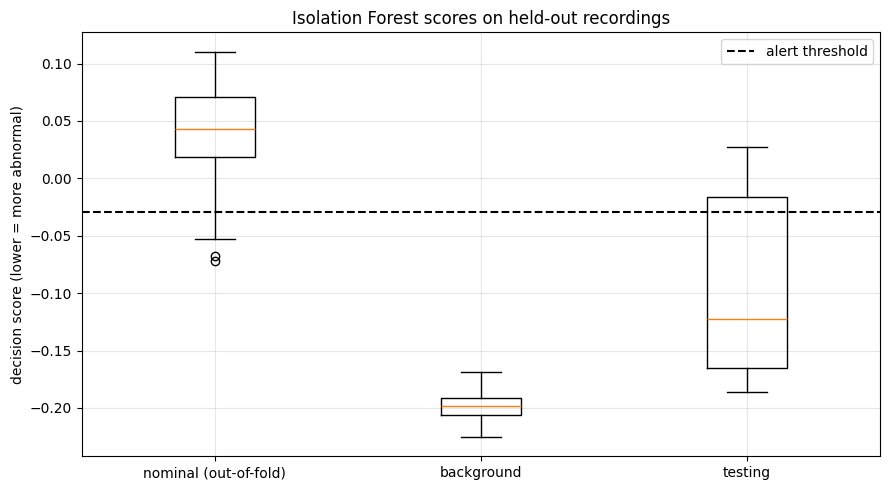

In [ ]:
import os, glob, json, cbor2, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

WIN, STEP = 100, 25
BANDS = [(0.5,5),(5,10),(10,20),(20,35),(35,50)]
PCTL, K, N = 2, 3, 5

def read_label_map(folder):
    p = os.path.join(folder, "info.labels")
    mp = {}
    if os.path.exists(p):
        info = json.load(open(p))
        for e in info.get("files", []):
            lab = e.get("label")
            lab = lab.get("label") if isinstance(lab, dict) else lab
            mp[os.path.basename(e["path"])] = lab
    return mp

def load(path):
    with open(path, "rb") as f:
        p = cbor2.load(f)["payload"]
    return np.asarray(p["values"], float), 1000 / p["interval_ms"], p

def features(v, fs):
    rows = []
    for s in range(0, len(v) - WIN + 1, STEP):
        w = v[s:s+WIN]; c = w - w.mean(0)
        r = {}
        for i in range(c.shape[1]):
            x = c[:, i]
            r[f"ax{i}_rms"] = np.sqrt(np.mean(x**2))
            r[f"ax{i}_p2p"] = x.max() - x.min()
            r[f"ax{i}_kurt"] = kurtosis(x)
        m = np.linalg.norm(c, axis=1)
        r["mag_rms"] = np.sqrt(np.mean(m**2)); r["mag_peak"] = m.max()
        P = (np.abs(np.fft.rfft(c * np.hanning(WIN)[:, None], axis=0))**2).sum(1)
        f = np.fft.rfftfreq(WIN, 1/fs); tot = P[1:].sum() + 1e-12
        for lo, hi in BANDS:
            r[f"band_{lo}_{hi}"] = P[(f >= lo) & (f < hi)].sum() / tot
        r["dom_freq"] = f[1:][np.argmax(P[1:])]
        r["centroid"] = (f[1:] * P[1:]).sum() / tot
        rows.append(r)
    return pd.DataFrame(rows)

# ---- load with labels taken from info.labels
recs = {}
for split in ["training", "testing"]:
    folder = f"{DATA_ROOT}/{split}"
    lmap = read_label_map(folder)
    for p in sorted(glob.glob(f"{folder}/*.cbor")):
        name = os.path.basename(p)
        v, fs, payload = load(p)
        X = features(v, fs)
        label = lmap.get(name) or name.split(".")[0]
        recs[name] = dict(split=split, label=label, X=X, secs=len(v)/fs,
                          fs=fs, shape=v.shape)

inv = pd.DataFrame([dict(file=k, split=r["split"], label=r["label"],
        seconds=round(r["secs"],1), fs_hz=r["fs"], axes=r["shape"][1], windows=len(r["X"]))
        for k, r in recs.items()])
display(inv.sort_values(["split","label"]))
print(inv.groupby(["split","label"]).size())

def make_model():
    return make_pipeline(RobustScaler(),
        IsolationForest(n_estimators=300, contamination="auto", random_state=42))

def persistent(flags):
    f = np.asarray(flags, int)
    if len(f) < N: return bool(f.sum() >= K)
    return bool((np.convolve(f, np.ones(N, int), "valid") >= K).any())

nom_train = [k for k, r in recs.items()
             if r["split"]=="training" and r["label"]=="nominal" and len(r["X"])>0]
print("\nNominal training files:", len(nom_train))

# ---- leave-one-recording-out on nominal training files
print("\nLeave-one-recording-out (nominal):")
oof = []
fa = []
for held in nom_train:
    rest = [k for k in nom_train if k != held]
    Xr = pd.concat([recs[k]["X"] for k in rest], ignore_index=True)
    m = make_model().fit(Xr)
    thr_i = np.percentile(m.decision_function(Xr), PCTL)
    s = m.decision_function(recs[held]["X"]); fl = s < thr_i
    oof.append(s); fa.append(fl.mean()*100)
    print(f"  {held}: {fl.mean()*100:.1f}% windows flagged, alert raised: {persistent(fl)}")
print(f"  mean false-flag rate: {np.mean(fa):.1f}%")

# ---- final model on all nominal training data
Xtr = pd.concat([recs[k]["X"] for k in nom_train], ignore_index=True)
model = make_model().fit(Xtr)
thr = np.percentile(model.decision_function(Xtr), PCTL)
print("\nTraining windows:", len(Xtr), "| threshold:", round(thr, 4))

rows = []
for k, r in recs.items():
    if len(r["X"]) == 0: continue
    s = model.decision_function(r["X"]); fl = s < thr
    r["scores"] = s
    rows.append(dict(file=k, split=r["split"], label=r["label"], windows=len(s),
                     flagged_pct=round(fl.mean()*100,1), mean_score=round(s.mean(),4),
                     alert=persistent(fl), used_for_training=k in nom_train))
res = pd.DataFrame(rows).sort_values(["label","split"])
display(res)

held = res[~res["used_for_training"]]
print("\nHeld-out summary by label:")
display(held.groupby("label").agg(files=("file","count"),
        mean_flagged_pct=("flagged_pct","mean"), alerts_raised=("alert","sum")))

# ---- AUROC vs held-out nominal (testing nominal if present, else out-of-fold)
test_nom = [r["scores"] for k, r in recs.items()
            if r["label"]=="nominal" and k not in nom_train and "scores" in r]
if test_nom:
    ref = np.concatenate(test_nom); ref_name = "held-out nominal test files"
else:
    ref = np.concatenate(oof); ref_name = "out-of-fold nominal (leave-one-out)"
print(f"\nAUROC reference set: {ref_name} ({len(ref)} windows)")
for lab in sorted({r["label"] for k, r in recs.items() if k not in nom_train} - {"nominal"}):
    ab = np.concatenate([r["scores"] for k, r in recs.items()
                         if r["label"]==lab and k not in nom_train and "scores" in r])
    y = np.r_[np.zeros(len(ref)), np.ones(len(ab))]
    print(f"AUROC nominal vs {lab}: {roc_auc_score(y, -np.r_[ref, ab]):.3f}  ({len(ab)} windows)")

# ---- plot
labs = sorted({r["label"] for k, r in recs.items() if k not in nom_train})
data = [np.concatenate([r["scores"] for k, r in recs.items()
        if r["label"]==l and k not in nom_train and "scores" in r]) for l in labs]
if "nominal" not in labs:
    labs = ["nominal (out-of-fold)"] + labs; data = [np.concatenate(oof)] + data
plt.figure(figsize=(9,5))
plt.boxplot(data, labels=labs)
plt.axhline(thr, color="k", ls="--", label="alert threshold")
plt.ylabel("decision score (lower = more abnormal)")
plt.title("Isolation Forest scores on held-out recordings")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("scores.png", dpi=200); plt.show()

joblib.dump(dict(model=model, threshold=thr, win=WIN, step=STEP, bands=BANDS, k=K, n=N),
            "isoforest_model.joblib")
!cp scores.png isoforest_model.joblib "/content/drive/MyDrive/Frontier day/"

training keys: ['version', 'files']
   {'path': 'background.3v08cg44.ingestion-6465d57cd7-7z7vg.cbor', 'name': 'background.3v08cg44', 'category': 'training', 'label': {'type': 'label', 'label': 'background'}}
   {'path': 'background.3v08kkng.ingestion-6465d57cd7-7z7vg.cbor', 'name': 'background.3v08kkng', 'category': 'training', 'label': {'type': 'label', 'label': 'background'}}
   {'path': 'background.3v08p2ho.ingestion-6465d57cd7-7z7vg.cbor', 'name': 'background.3v08p2ho', 'category': 'training', 'label': {'type': 'label', 'label': 'background'}}
testing keys: ['version', 'files']
   {'path': 'testing.3v0a5go7.ingestion-6465d57cd7-6v9f9.cbor', 'name': 'testing.3v0a5go7', 'category': 'testing', 'label': {'type': 'label', 'label': 'testing'}}
   {'path': 'testing.3v0a63l4.ingestion-6465d57cd7-6v9f9.cbor', 'name': 'testing.3v0a63l4', 'category': 'testing', 'label': {'type': 'label', 'label': 'testing'}}
   {'path': 'testing.3v0a75fh.ingestion-6465d57cd7-6v9f9.cbor', 'name': 'testing.3v0

,mag_rms,dom_freq,centroid
label,,,
background,0.073049,26.540541,25.559105
nominal,1.346451,46.000000,31.966351
testing,2.653310,38.851852,32.276776


,label,file,mag_rms,dom_freq,centroid
18,testing,testing.3v0a5go7.i,1.447528,46.000000,32.079026
19,testing,testing.3v0a63l4.i,1.869558,25.888889,29.647175
20,testing,testing.3v0a75fh.i,4.642845,44.666667,35.104128


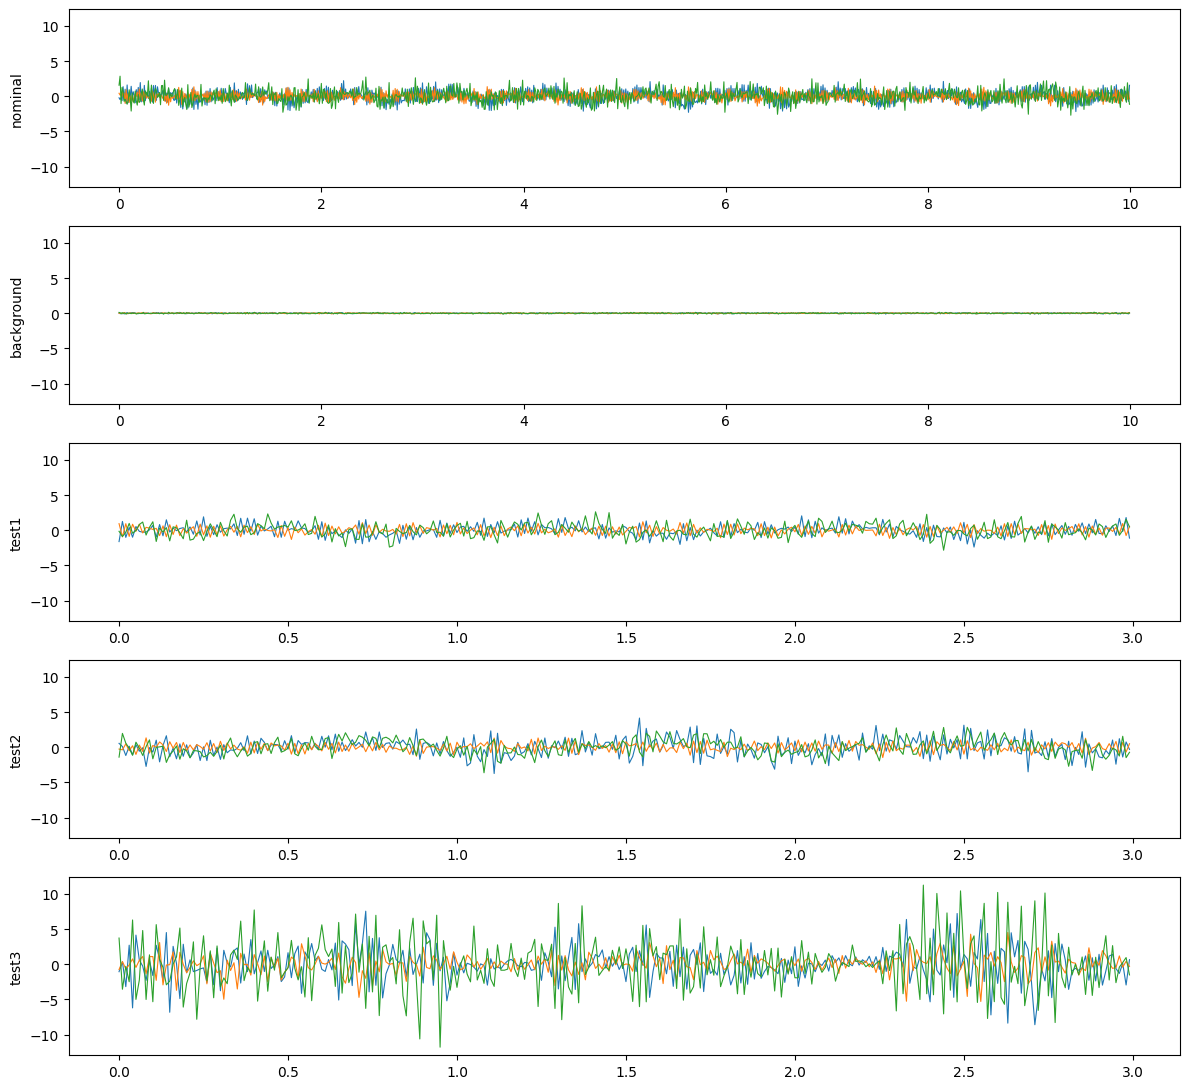

In [ ]:
import json
for split in ["training", "testing"]:
    info = json.load(open(f"{DATA_ROOT}/{split}/info.labels"))
    print(split, "keys:", list(info.keys()))
    for e in info["files"][:3]:
        print("  ", e)

rows = [dict(label=r["label"], file=k[:18], mag_rms=r["X"]["mag_rms"].mean(),
             dom_freq=r["X"]["dom_freq"].mean(), centroid=r["X"]["centroid"].mean())
        for k, r in recs.items()]
df = pd.DataFrame(rows)
display(df.groupby("label")[["mag_rms","dom_freq","centroid"]].mean())
display(df[df.label=="testing"])

# raw signals side by side
pick = {"nominal": sorted(glob.glob(f"{DATA_ROOT}/training/nominal*.cbor"))[0],
        "background": sorted(glob.glob(f"{DATA_ROOT}/training/background*.cbor"))[0]}
for i, p in enumerate(sorted(glob.glob(f"{DATA_ROOT}/testing/*.cbor"))):
    pick[f"test{i+1}"] = p
fig, ax = plt.subplots(len(pick), 1, figsize=(12, 2.2*len(pick)), sharey=True)
for a, (n, p) in zip(ax, pick.items()):
    v, fs, _ = load(p); t = np.arange(len(v))/fs
    a.plot(t, v - v.mean(0), lw=.8); a.set_ylabel(n)
plt.tight_layout(); plt.savefig("raw_compare.png", dpi=200); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
OWN = "/content/drive/MyDrive/Frontier day/Own_data"
print(sorted(os.listdir(OWN)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['loose_01', 'loose_02', 'loose_03', 'nominal_01', 'nominal_02', 'nominal_03', 'nominal_04', 'nominal_05', 'nominal_06', 'obstruct_01', 'obstruct_02', 'obstruct_03', 'off_01', 'off_02']


In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/Frontier day"
print("Frontier day contents:", os.listdir(BASE))

for root, dirs, files in os.walk(BASE):
    if "own" in root.lower() or any(f.lower().endswith((".csv", ".xls", ".xlsx", ".zip", ".txt")) for f in files):
        print("\n", root)
        for f in sorted(files)[:40]:
            print("   ", f)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Frontier day contents: ['industrial_-fan-anomaly-detection-demo-(accelerometer)-export.zip', 'machine_data', 'Own_data', 'raw_compare.png', 'scores.png', 'isoforest_model.joblib', 'own_scores.png', 'own_raw_compare.png', 'own_inventory.csv', 'own_results.csv', 'own_isoforest_model.joblib', 'own_results_v2.csv', 'own_rule_sweep.csv', 'edge_impulse_loo.csv', 'edge_impulse_background.csv']

 /content/drive/MyDrive/Frontier day
    edge_impulse_background.csv
    edge_impulse_loo.csv
    industrial_-fan-anomaly-detection-demo-(accelerometer)-export.zip
    isoforest_model.joblib
    own_inventory.csv
    own_isoforest_model.joblib
    own_raw_compare.png
    own_results.csv
    own_results_v2.csv
    own_rule_sweep.csv
    own_scores.png
    raw_compare.png
    scores.png

 /content/drive/MyDrive/Frontier day/machine_data
    README.txt
    info.labels

 /content

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found 14 files
Inspecting first file: loose_01
  zip contents: ['Raw Data.csv', 'meta/device.csv', 'meta/time.csv']
  using: Raw Data.csv
  columns: ['Time (s)', 'Linear Acceleration x (m/s^2)', 'Linear Acceleration y (m/s^2)', 'Linear Acceleration z (m/s^2)', 'Absolute acceleration (m/s^2)']


,Time (s),Linear Acceleration x (m/s^2),Linear Acceleration y (m/s^2),Linear Acceleration z (m/s^2),Absolute acceleration (m/s^2)
0,0.021915,0.005077,-0.003052,-0.142470,0.142593
1,0.029872,-0.182188,-0.077328,-0.273406,0.337525
2,0.038150,0.162954,-0.285828,0.122640,0.351130


Loaded 14 of 14
Labels found: ['loose', 'nominal', 'obstruct', 'off']
Native sampling rates (Hz): min 122, median 122, max 122
Using FS=100 Hz, window=100 samples, bands=[(0.5, 5), (5, 10), (10, 20), (20, 35), (35, 50)]


,file,label,native_hz,seconds,windows
0,loose_01,loose,122,24.0,93
1,loose_02,loose,122,24.0,92
2,loose_03,loose,122,24.0,92
3,nominal_01,nominal,122,25.4,98
4,nominal_02,nominal,122,26.8,104
5,nominal_03,nominal,122,24.9,96
6,nominal_04,nominal,122,24.0,92
7,nominal_05,nominal,122,24.0,92
8,nominal_06,nominal,122,24.0,93
9,obstruct_01,obstruct,122,24.0,92


label
loose       3
nominal     6
obstruct    3
off         2
dtype: int64

Train nominal: ['nominal_01', 'nominal_02', 'nominal_03', 'nominal_04']
Held-out nominal: ['nominal_05', 'nominal_06']

Leave-one-recording-out on training nominal:
  nominal_01: 29.6% flagged, alert: True
  nominal_02: 9.6% flagged, alert: True
  nominal_03: 6.2% flagged, alert: True
  nominal_04: 15.2% flagged, alert: True
  mean false-flag rate: 15.2%

Training windows: 390 | threshold: -0.0556


,file,label,windows,flagged_pct,mean_score,alert,role
0,loose_01,loose,93,100.0,-0.1069,True,held-out
1,loose_02,loose,92,79.3,-0.0802,True,held-out
2,loose_03,loose,92,26.1,-0.0473,True,held-out
3,nominal_01,nominal,98,4.1,0.0278,False,train
4,nominal_02,nominal,104,0.0,0.0522,False,train
5,nominal_03,nominal,96,3.1,0.0625,True,train
6,nominal_04,nominal,92,1.1,0.0535,False,train
7,nominal_05,nominal,92,2.2,-0.0155,False,held-out
8,nominal_06,nominal,93,3.2,-0.0154,False,held-out
9,obstruct_01,obstruct,92,6.5,-0.0046,True,held-out



Held-out summary (never used for training):


,files,mean_flagged_pct,alerts
label,,,
loose,3,68.466667,3
nominal,2,2.700000,0
obstruct,3,20.633333,3
off,2,100.000000,2



Mean vibration by condition:


,mag_rms,dom_freq
label,,
loose,0.416,22.252
nominal,0.310,23.992
obstruct,0.349,24.069
off,0.009,21.924



AUROC (held-out nominal vs condition):
  loose: 0.945
  obstruct: 0.516
  off: 1.000


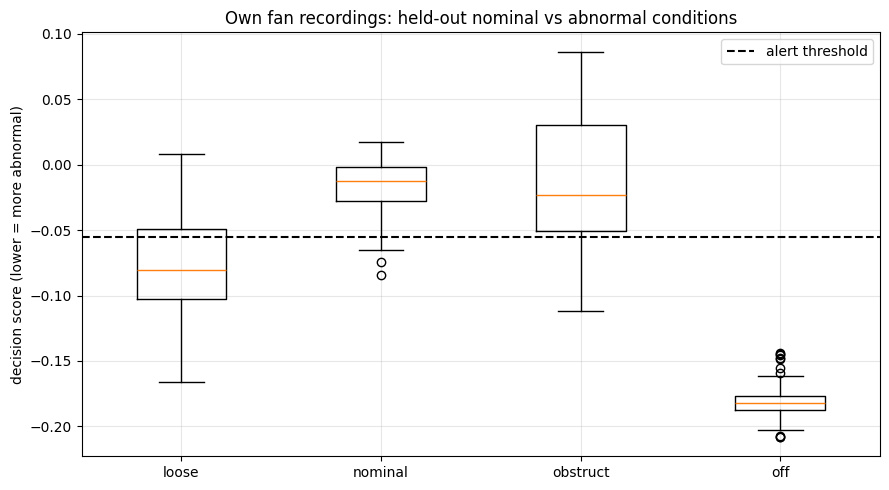

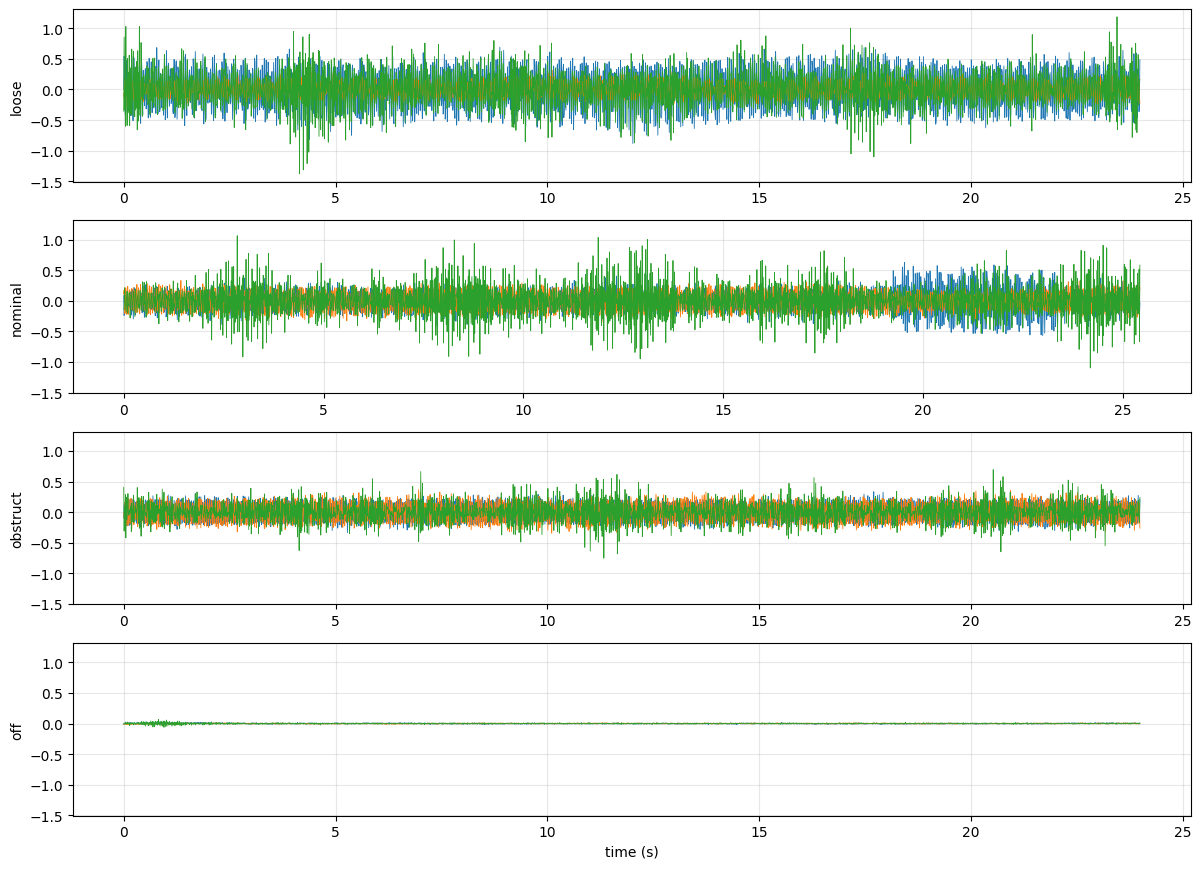


Saved to /content/drive/MyDrive/Frontier day


In [ ]:
!pip -q install openpyxl
import os, io, glob, shutil, zipfile, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kurtosis
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from google.colab import drive

drive.mount('/content/drive')

BASE = "/content/drive/MyDrive/Frontier day"
OWN  = f"{BASE}/Own_data"
PCTL, K, N = 2, 3, 5            # threshold percentile, k-of-n persistence
TRIM_S = 3                      # drop first/last 3 s (hands moving)

# ---------------------------------------------------------------- loading
def pick_inner(zf):
    names = [n for n in zf.namelist() if not n.endswith("/")]
    csvs = [n for n in names if n.lower().endswith((".csv", ".tsv", ".txt"))]
    data = [n for n in csvs if "meta" not in n.lower()]
    pref = [n for n in data if any(w in n.lower() for w in ("accel", "raw"))]
    pool = pref or data or csvs
    return max(pool, key=lambda n: zf.getinfo(n).file_size) if pool else None

def load_table(path, verbose=False):
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as zf:
            names = zf.namelist()
            if "xl/workbook.xml" in names:                       # real xlsx
                d = pd.read_excel(path, sheet_name=0, engine="openpyxl")
            else:                                                # phyphox zip of CSVs
                inner = pick_inner(zf)
                if inner is None:
                    raise ValueError(f"no csv inside; contents: {names}")
                if verbose:
                    print("  zip contents:", names)
                    print("  using:", inner)
                d = pd.read_csv(io.BytesIO(zf.read(inner)), sep=None, engine="python")
    else:
        d = pd.read_csv(path, sep=None, engine="python")
    if verbose:
        print("  columns:", list(d.columns))
        display(d.head(3))
    d = d.apply(pd.to_numeric, errors="coerce")
    t = d.iloc[:, 0].to_numpy(float)
    xyz = d.iloc[:, 1:4].to_numpy(float)
    ok = np.isfinite(t) & np.isfinite(xyz).all(1)
    t, xyz = t[ok], xyz[ok]
    order = np.argsort(t)
    t, xyz = t[order], xyz[order]
    keep = np.r_[True, np.diff(t) > 0]
    return t[keep], xyz[keep]

paths = sorted(p for p in glob.glob(f"{OWN}/*") if os.path.isfile(p))
print("Found", len(paths), "files")
assert paths, f"No files found in {OWN}"

raw = {}
for i, p in enumerate(paths):
    name = os.path.basename(p)
    try:
        if i == 0:
            print("Inspecting first file:", name)
        t, xyz = load_table(p, verbose=(i == 0))
    except Exception as e:
        print("  could not read", name, "->", e); continue
    label = name.split("_")[0].split(".")[0].lower()
    raw[name] = dict(label=label, t=t, xyz=xyz, native=1 / np.median(np.diff(t)))

print("Loaded", len(raw), "of", len(paths))
assert raw, "Nothing could be read - send me the messages above"
print("Labels found:", sorted({r["label"] for r in raw.values()}))
natives = np.array([r["native"] for r in raw.values()])
print("Native sampling rates (Hz): min %.0f, median %.0f, max %.0f" %
      (natives.min(), np.median(natives), natives.max()))

# ---------------------------------------------- common sampling rate + features
FS = int(min(100, np.floor(np.median(natives) / 10) * 10))
WIN, STEP = FS, FS // 4                       # 1 s windows, 75% overlap
nyq = FS / 2
BANDS = [(lo, min(hi, nyq)) for lo, hi in [(0.5, 5), (5, 10), (10, 20), (20, 35), (35, 50)] if lo < nyq]
print(f"Using FS={FS} Hz, window={WIN} samples, bands={BANDS}")

def resample(t, xyz):
    tt = np.arange(t[0], t[-1], 1 / FS)
    v = np.column_stack([np.interp(tt, t, xyz[:, i]) for i in range(3)])
    return v[TRIM_S * FS: -TRIM_S * FS]

def features(v):
    rows = []
    for s in range(0, len(v) - WIN + 1, STEP):
        w = v[s:s + WIN]; c = w - w.mean(0)
        r = {}
        for i, a in enumerate("XYZ"):
            x = c[:, i]
            r[f"{a}_rms"] = np.sqrt(np.mean(x ** 2))
            r[f"{a}_p2p"] = x.max() - x.min()
            r[f"{a}_kurt"] = kurtosis(x)
        m = np.linalg.norm(c, axis=1)
        r["mag_rms"] = np.sqrt(np.mean(m ** 2)); r["mag_peak"] = m.max()
        P = (np.abs(np.fft.rfft(c * np.hanning(WIN)[:, None], axis=0)) ** 2).sum(1)
        f = np.fft.rfftfreq(WIN, 1 / FS); tot = P[1:].sum() + 1e-12
        for lo, hi in BANDS:
            r[f"band_{lo}_{hi}"] = P[(f >= lo) & (f < hi)].sum() / tot
        r["dom_freq"] = f[1:][np.argmax(P[1:])]
        r["centroid"] = (f[1:] * P[1:]).sum() / tot
        rows.append(r)
    return pd.DataFrame(rows)

own = {}
for name, r in raw.items():
    v = resample(r["t"], r["xyz"])
    X = features(v)
    if len(X) == 0:
        print("  skipped (too short after trimming):", name); continue
    own[name] = dict(label=r["label"], v=v, X=X, native=r["native"])

inv = pd.DataFrame([dict(file=k, label=r["label"], native_hz=round(r["native"]),
                         seconds=round(len(r["v"]) / FS, 1), windows=len(r["X"]))
                    for k, r in own.items()])
display(inv)
print(inv.groupby("label").size())

# ---------------------------------------------------------------- helpers
def make_model():
    return make_pipeline(RobustScaler(),
        IsolationForest(n_estimators=300, contamination="auto", random_state=42))

def persistent(flags):
    f = np.asarray(flags, int)
    if len(f) < N: return bool(f.sum() >= K)
    return bool((np.convolve(f, np.ones(N, int), "valid") >= K).any())

# ------------------------------------------------------- split nominal files
nom = sorted(k for k, r in own.items() if r["label"] == "nominal")
assert len(nom) >= 3, "Need at least 3 nominal recordings"
n_hold = 2 if len(nom) >= 5 else 1
train_names, test_nom = nom[:-n_hold], nom[-n_hold:]
print("\nTrain nominal:", train_names)
print("Held-out nominal:", test_nom)

# ------------------------------------- leave-one-recording-out (false alarms)
print("\nLeave-one-recording-out on training nominal:")
fa = []
for held in train_names:
    rest = [k for k in train_names if k != held]
    Xr = pd.concat([own[k]["X"] for k in rest], ignore_index=True)
    m = make_model().fit(Xr)
    thr_i = np.percentile(m.decision_function(Xr), PCTL)
    fl = m.decision_function(own[held]["X"]) < thr_i
    fa.append(fl.mean() * 100)
    print(f"  {held}: {fl.mean()*100:.1f}% flagged, alert: {persistent(fl)}")
print(f"  mean false-flag rate: {np.mean(fa):.1f}%")

# ------------------------------------------ final model (own nominal only)
Xtr = pd.concat([own[k]["X"] for k in train_names], ignore_index=True)
model = make_model().fit(Xtr)
thr = np.percentile(model.decision_function(Xtr), PCTL)
print("\nTraining windows:", len(Xtr), "| threshold:", round(thr, 4))

rows = []
for k, r in own.items():
    s = model.decision_function(r["X"]); fl = s < thr
    r["scores"] = s
    rows.append(dict(file=k, label=r["label"], windows=len(s),
                     flagged_pct=round(fl.mean() * 100, 1), mean_score=round(s.mean(), 4),
                     alert=persistent(fl),
                     role="train" if k in train_names else "held-out"))
res = pd.DataFrame(rows).sort_values(["label", "file"])
display(res)

print("\nHeld-out summary (never used for training):")
display(res[res.role == "held-out"].groupby("label").agg(
    files=("file", "count"), mean_flagged_pct=("flagged_pct", "mean"), alerts=("alert", "sum")))

lvl = pd.DataFrame([dict(label=r["label"], mag_rms=r["X"]["mag_rms"].mean(),
                         dom_freq=r["X"]["dom_freq"].mean()) for r in own.values()])
print("\nMean vibration by condition:")
display(lvl.groupby("label").mean().round(3))

# ------------------------------------------- AUROC: held-out nominal vs rest
ref = np.concatenate([own[k]["scores"] for k in test_nom])
print("\nAUROC (held-out nominal vs condition):")
for lab in sorted({r["label"] for r in own.values()} - {"nominal"}):
    ab = np.concatenate([r["scores"] for r in own.values() if r["label"] == lab])
    y = np.r_[np.zeros(len(ref)), np.ones(len(ab))]
    print(f"  {lab}: {roc_auc_score(y, -np.r_[ref, ab]):.3f}")

# ---------------------------------------------------------------- figures
labs = sorted({r["label"] for r in own.values()})
data = [np.concatenate([r["scores"] for k, r in own.items()
        if r["label"] == l and (l != "nominal" or k in test_nom)]) for l in labs]
plt.figure(figsize=(9, 5))
try:
    plt.boxplot(data, tick_labels=labs)
except TypeError:
    plt.boxplot(data, labels=labs)
plt.axhline(thr, color="k", ls="--", label="alert threshold")
plt.ylabel("decision score (lower = more abnormal)")
plt.title("Own fan recordings: held-out nominal vs abnormal conditions")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig("own_scores.png", dpi=200); plt.show()

fig, ax = plt.subplots(len(labs), 1, figsize=(12, 2.2 * len(labs)), sharey=True)
for a, l in zip(np.atleast_1d(ax), labs):
    k = next(k for k, r in own.items() if r["label"] == l)
    v = own[k]["v"]; a.plot(np.arange(len(v)) / FS, v - v.mean(0), lw=.6)
    a.set_ylabel(l); a.grid(alpha=.3)
plt.xlabel("time (s)"); plt.tight_layout()
plt.savefig("own_raw_compare.png", dpi=200); plt.show()

# ------------------------------------------------------------ save outputs
joblib.dump(dict(model=model, threshold=thr, fs=FS, win=WIN, step=STEP, bands=BANDS, k=K, n=N),
            "own_isoforest_model.joblib")
res.to_csv("own_results.csv", index=False)
inv.to_csv("own_inventory.csv", index=False)
for f in ["own_scores.png", "own_raw_compare.png", "own_isoforest_model.joblib",
          "own_results.csv", "own_inventory.csv"]:
    shutil.copy(f, BASE)
print("\nSaved to", BASE)

In [ ]:
def persistent_kn(flags, k, n):
    f = np.asarray(flags, int)
    if len(f) < n: return bool(f.sum() >= k)
    return bool((np.convolve(f, np.ones(n, int), "valid") >= k).any())

def first_alert_s(flags, k, n):
    f = np.asarray(flags, int)
    if len(f) < n: return None
    c = np.convolve(f, np.ones(n, int), "valid") >= k
    return None if not c.any() else round((int(np.argmax(c)) + n - 1) * STEP / FS + WIN / FS, 1)

def loo_flags(pctl):
    out = {}
    for held in train_names:
        rest = [k for k in train_names if k != held]
        Xr = pd.concat([own[k]["X"] for k in rest], ignore_index=True)
        m = make_model().fit(Xr)
        thr_i = np.percentile(m.decision_function(Xr), pctl)
        out[held] = m.decision_function(own[held]["X"]) < thr_i
    return out

# ---- sweep, using ONLY leave-one-out on training nominal files
rows = []
for pctl in [1, 2, 5]:
    lf = loo_flags(pctl)
    for k, n in [(3, 5), (8, 12), (12, 20), (20, 28), (30, 40)]:
        rows.append(dict(pctl=pctl, k=k, n=n,
                         span_s=round((n - 1) * STEP / FS + WIN / FS, 1),
                         false_alerts=sum(persistent_kn(f, k, n) for f in lf.values()),
                         mean_flag_pct=round(np.mean([f.mean() * 100 for f in lf.values()]), 1)))
sweep = pd.DataFrame(rows)
display(sweep)

best = sweep.sort_values(["false_alerts", "n", "pctl"]).iloc[0]
print("\nChosen rule (fewest LOO false alerts, then fastest):")
print(best.to_dict())
P2, K2, N2 = int(best.pctl), int(best.k), int(best.n)

# ---- apply the chosen rule once to every recording (model trained on train_names)
thr2 = np.percentile(model.decision_function(Xtr), P2)
rows = []
for name, r in own.items():
    fl = model.decision_function(r["X"]) < thr2
    rows.append(dict(file=name, label=r["label"],
                     role="train" if name in train_names else "held-out",
                     flagged_pct=round(fl.mean() * 100, 1),
                     alert=persistent_kn(fl, K2, N2),
                     first_alert_s=first_alert_s(fl, K2, N2)))
v2 = pd.DataFrame(rows).sort_values(["label", "file"])
display(v2)
print("\nHeld-out summary, v2 rule:")
display(v2[v2.role == "held-out"].groupby("label").agg(
    files=("file", "count"), mean_flagged_pct=("flagged_pct", "mean"), alerts=("alert", "sum")))

v2.to_csv("own_results_v2.csv", index=False); sweep.to_csv("own_rule_sweep.csv", index=False)
shutil.copy("own_results_v2.csv", BASE); shutil.copy("own_rule_sweep.csv", BASE)

,pctl,k,n,span_s,false_alerts,mean_flag_pct
0,1,3,5,2.0,3,10.2
1,1,8,12,3.8,0,10.2
2,1,12,20,5.8,0,10.2
3,1,20,28,7.8,0,10.2
4,1,30,40,10.8,0,10.2
5,2,3,5,2.0,4,15.2
6,2,8,12,3.8,1,15.2
7,2,12,20,5.8,1,15.2
8,2,20,28,7.8,0,15.2
9,2,30,40,10.8,0,15.2



Chosen rule (fewest LOO false alerts, then fastest):
{'pctl': 1.0, 'k': 8.0, 'n': 12.0, 'span_s': 3.8, 'false_alerts': 0.0, 'mean_flag_pct': 10.2}


,file,label,role,flagged_pct,alert,first_alert_s
0,loose_01,loose,held-out,96.8,True,3.8
1,loose_02,loose,held-out,60.9,True,5.0
2,loose_03,loose,held-out,18.5,False,NaN
3,nominal_01,nominal,train,3.1,False,NaN
4,nominal_02,nominal,train,0.0,False,NaN
5,nominal_03,nominal,train,1.0,False,NaN
6,nominal_04,nominal,train,0.0,False,NaN
7,nominal_05,nominal,held-out,2.2,False,NaN
8,nominal_06,nominal,held-out,0.0,False,NaN
9,obstruct_01,obstruct,held-out,1.1,False,NaN



Held-out summary, v2 rule:


,files,mean_flagged_pct,alerts
label,,,
loose,3,58.733333,2
nominal,2,1.100000,0
obstruct,3,9.433333,1
off,2,100.000000,2


'/content/drive/MyDrive/Frontier day/own_rule_sweep.csv'

In [ ]:
!pip -q install cbor2
import cbor2, zipfile

zip_path = glob.glob(f"{BASE}/industrial*.zip")[0]
EDGE = "/content/edge_data"
with zipfile.ZipFile(zip_path) as z:
    z.extractall(EDGE)
root = next(r for r, d, _ in os.walk(EDGE) if "training" in d and "testing" in d)
print("Dataset folder:", root)

def load_cbor(path):
    with open(path, "rb") as f:
        p = cbor2.load(f)["payload"]
    return np.asarray(p["values"], float), 1000 / p["interval_ms"]

ei = {}
for p in sorted(glob.glob(f"{root}/training/*.cbor")):
    v, fs = load_cbor(p)
    assert abs(fs - FS) < 1e-6 and v.shape[1] == 3, f"unexpected format in {p}"
    ei[os.path.basename(p)] = dict(label=os.path.basename(p).split(".")[0], X=features(v))

ei_nom = sorted(k for k, r in ei.items() if r["label"] == "nominal")
ei_bg  = sorted(k for k, r in ei.items() if r["label"] == "background")
print(f"nominal files: {len(ei_nom)} | background files: {len(ei_bg)}")

# ---- leave-one-recording-out with the FINAL rule (pctl P2, K2 of N2)
print(f"\nLeave-one-recording-out, rule = {K2} of {N2} windows, threshold at {P2}th percentile")
rows = []
for held in ei_nom:
    rest = [k for k in ei_nom if k != held]
    Xr = pd.concat([ei[k]["X"] for k in rest], ignore_index=True)
    m = make_model().fit(Xr)
    thr_i = np.percentile(m.decision_function(Xr), P2)
    fl = m.decision_function(ei[held]["X"]) < thr_i
    rows.append(dict(file=held[:20], flagged_pct=round(fl.mean() * 100, 1),
                     alert=persistent_kn(fl, K2, N2)))
loo = pd.DataFrame(rows)
display(loo)
print(f"mean flagged: {loo.flagged_pct.mean():.1f}% | false alerts: {int(loo.alert.sum())} of {len(loo)} recordings")

# ---- final model on all 9 nominal, score background (state check only)
Xe = pd.concat([ei[k]["X"] for k in ei_nom], ignore_index=True)
me = make_model().fit(Xe)
te = np.percentile(me.decision_function(Xe), P2)
rows = []
for k in ei_bg:
    fl = me.decision_function(ei[k]["X"]) < te
    rows.append(dict(file=k[:20], flagged_pct=round(fl.mean() * 100, 1),
                     alert=persistent_kn(fl, K2, N2), first_alert_s=first_alert_s(fl, K2, N2)))
bg = pd.DataFrame(rows)
display(bg)
print(f"background: {int(bg.alert.sum())} of {len(bg)} recordings raised an alert")

lvl = pd.concat([ei[k]["X"].assign(label=ei[k]["label"]) for k in ei_nom + ei_bg])
display(lvl.groupby("label")[["mag_rms", "dom_freq"]].mean().round(3))

loo.to_csv("edge_impulse_loo.csv", index=False); bg.to_csv("edge_impulse_background.csv", index=False)
shutil.copy("edge_impulse_loo.csv", BASE); shutil.copy("edge_impulse_background.csv", BASE)

Dataset folder: /content/edge_data
nominal files: 9 | background files: 9

Leave-one-recording-out, rule = 8 of 12 windows, threshold at 1th percentile


,file,flagged_pct,alert
0,nominal.3v091ruq.ing,5.4,False
1,nominal.3v092e54.ing,5.4,False
2,nominal.3v0931vt.ing,0.0,False
3,nominal.3v093ms6.ing,0.0,False
4,nominal.3v09515h.ing,0.0,False
5,nominal.3v0966gj.ing,0.0,False
6,nominal.3v0979vr.ing,0.0,False
7,nominal.3v0999m3.ing,2.7,False
8,nominal.3v099th3.ing,0.0,False


mean flagged: 1.5% | false alerts: 0 of 9 recordings


,file,flagged_pct,alert,first_alert_s
0,background.3v08cg44.,100.0,True,3.8
1,background.3v08kkng.,100.0,True,3.8
2,background.3v08p2ho.,100.0,True,3.8
3,background.3v08pl9k.,100.0,True,3.8
4,background.3v08q7f1.,100.0,True,3.8
5,background.3v08r6dc.,100.0,True,3.8
6,background.3v08rqrs.,100.0,True,3.8
7,background.3v08scop.,100.0,True,3.8
8,background.3v08v0hc.,100.0,True,3.8


background: 9 of 9 recordings raised an alert


,mag_rms,dom_freq
label,,
background,0.073,26.541
nominal,1.346,46.000


'/content/drive/MyDrive/Frontier day/edge_impulse_background.csv'

Metrics cell

In [ ]:
# Paste into the SAME Colab notebook, after the pipeline + rule-sweep cells.
# Reuses: make_model, persistent_kn, P2, K2, N2 from those cells.
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score

# ---------------- EDIT THESE TWO LINES ----------------
recs = own                      # {name: dict(label="nominal"/"off"/"obstruct"/"loose", X=feature DataFrame)}
train_names = ["nominal_01", "nominal_02", "nominal_03", "nominal_04"]   # the 4 nominal files used to train
# -------------------------------------------------------

rng = np.random.default_rng(0)
nominal = [k for k, r in recs.items() if r["label"] == "nominal"]
held = [k for k in nominal if k not in train_names]
abn = [k for k, r in recs.items() if r["label"] != "nominal"]
print(f"train: {len(train_names)} | held-out nominal: {held} | abnormal: {len(abn)}")

Xtr = pd.concat([recs[k]["X"] for k in train_names], ignore_index=True)
m = make_model().fit(Xtr)
thr = np.percentile(m.decision_function(Xtr), P2)

# ---- score every test recording
rows, sc = [], {}
for k in held + abn:
    s = m.decision_function(recs[k]["X"]); sc[k] = s
    fl = s < thr
    rows.append(dict(file=k, label=recs[k]["label"], truth=int(k in abn),
                     windows=len(s), flagged_pct=round(100 * fl.mean(), 1),
                     alert=int(persistent_kn(fl, K2, N2))))
rec = pd.DataFrame(rows)
display(rec)

def prf(tp, fp, fn, tn):
    p = tp / (tp + fp) if tp + fp else np.nan
    r = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * p * r / (p + r) if p == p and r == r and p + r else np.nan
    return p, r, f1, (tp + tn) / (tp + fp + fn + tn)

# ---- recording level (the headline numbers)
tp = ((rec.truth == 1) & (rec.alert == 1)).sum(); fn = ((rec.truth == 1) & (rec.alert == 0)).sum()
fp = ((rec.truth == 0) & (rec.alert == 1)).sum(); tn = ((rec.truth == 0) & (rec.alert == 0)).sum()
p, r, f1, acc = prf(tp, fp, fn, tn)
print(f"\nRECORDING level  TP={tp} FN={fn} FP={fp} TN={tn}")
print(f"precision={p:.2f} recall={r:.2f} F1={f1:.2f} accuracy={acc:.2f}")

# ---- window level (windows overlap 75%, so they are NOT independent: treat as descriptive)
y = np.concatenate([np.full(len(sc[k]), int(k in abn)) for k in sc])
s_all = np.concatenate([sc[k] for k in sc]); yp = (s_all < thr).astype(int)
tp, fp = ((y == 1) & (yp == 1)).sum(), ((y == 0) & (yp == 1)).sum()
fn, tn = ((y == 1) & (yp == 0)).sum(), ((y == 0) & (yp == 0)).sum()
p, r, f1, acc = prf(tp, fp, fn, tn)
print(f"\nWINDOW level     TP={tp} FN={fn} FP={fp} TN={tn}")
print(f"precision={p:.2f} recall={r:.2f} F1={f1:.2f} accuracy={acc:.2f} "
      f"balanced_acc={(r + tn / (tn + fp)) / 2:.2f}")
print(f"pooled window AUROC = {roc_auc_score(y, -s_all):.3f}")

# ---- AUROC per abnormal condition vs held-out nominal
print("\nAUROC per condition (vs held-out nominal windows):")
nom_s = np.concatenate([sc[k] for k in held])
for lab in sorted({recs[k]["label"] for k in abn}):
    a = np.concatenate([sc[k] for k in abn if recs[k]["label"] == lab])
    auc = roc_auc_score(np.r_[np.zeros(len(nom_s)), np.ones(len(a))], -np.r_[nom_s, a])
    print(f"  {lab:10s} {auc:.3f}")

# ---- bootstrap 95% CI, resampling RECORDINGS (not windows)
def boot(n=2000):
    P, R = [], []
    A, N = rec[rec.truth == 1].alert.values, rec[rec.truth == 0].alert.values
    for _ in range(n):
        a = rng.choice(A, len(A)); nn = rng.choice(N, len(N))
        tp, fn, fp = a.sum(), (1 - a).sum(), nn.sum()
        P.append(tp / (tp + fp) if tp + fp else np.nan); R.append(tp / (tp + fn))
    return np.nanpercentile(P, [2.5, 97.5]), np.nanpercentile(R, [2.5, 97.5])
pc, rc = boot()
print(f"\nBootstrap 95% CI  precision {pc[0]:.2f}-{pc[1]:.2f} | recall {rc[0]:.2f}-{rc[1]:.2f}")
print("(wide on purpose: only a handful of recordings)")

rec.to_csv("own_metrics_recordings.csv", index=False)

train: 4 | held-out nominal: ['nominal_05', 'nominal_06'] | abnormal: 8


,file,label,truth,windows,flagged_pct,alert
0,nominal_05,nominal,0,92,2.2,0
1,nominal_06,nominal,0,93,0.0,0
2,loose_01,loose,1,93,96.8,1
3,loose_02,loose,1,92,60.9,1
4,loose_03,loose,1,92,18.5,0
5,obstruct_01,obstruct,1,92,1.1,0
6,obstruct_02,obstruct,1,92,3.3,0
7,obstruct_03,obstruct,1,92,23.9,1
8,off_01,off,1,92,100.0,1
9,off_02,off,1,92,100.0,1



RECORDING level  TP=5 FN=3 FP=0 TN=2
precision=1.00 recall=0.62 F1=0.77 accuracy=0.70

WINDOW level     TP=373 FN=364 FP=2 TN=183
precision=0.99 recall=0.51 F1=0.67 accuracy=0.60 balanced_acc=0.75
pooled window AUROC = 0.798

AUROC per condition (vs held-out nominal windows):
  loose      0.945
  obstruct   0.516
  off        1.000

Bootstrap 95% CI  precision 1.00-1.00 | recall 0.25-0.88
(wide on purpose: only a handful of recordings)


Compare detectors

In [ ]:
# Paste into the SAME Colab notebook, after metrics_cell.py has run
# (it reuses recs, train_names, held, abn, make_model, persistent_kn, P2, K2, N2).
# Compares three detectors with the SAME split, threshold rule and alert rule.
import numpy as np, pandas as pd
from sklearn.covariance import LedoitWolf
from sklearn.metrics import roc_auc_score

Xtr = pd.concat([recs[k]["X"] for k in train_names], ignore_index=True)
cols = list(Xtr.columns)

# ---- each detector returns an ABNORMALITY score (higher = more abnormal)
def fit_iforest(X):
    m = make_model().fit(X)
    return lambda Z: -m.decision_function(Z)

def fit_zscore(X):
    mu, sd = X.mean().values, X.std().values + 1e-9
    return lambda Z: np.sqrt((((Z[cols].values - mu) / sd) ** 2).mean(axis=1))

def fit_mahalanobis(X):
    lw = LedoitWolf().fit(X[cols].values)          # shrinkage = stable with little data
    return lambda Z: np.sqrt(lw.mahalanobis(Z[cols].values))

detectors = {"IsolationForest": fit_iforest, "Z-score": fit_zscore, "Mahalanobis": fit_mahalanobis}

summary, per_file = [], []
for name, fit in detectors.items():
    score = fit(Xtr)
    thr = np.percentile(score(Xtr), 100 - P2)      # same "1st percentile" idea, flipped sign
    res = {}
    for k in held + abn:
        s = score(recs[k]["X"]); fl = s > thr
        res[k] = (s, fl, int(persistent_kn(fl, K2, N2)))
        per_file.append(dict(detector=name, file=k, label=recs[k]["label"],
                             flagged_pct=round(100 * fl.mean(), 1), alert=res[k][2]))
    tp = sum(res[k][2] for k in abn);   fn = len(abn) - tp
    fp = sum(res[k][2] for k in held);  tn = len(held) - fp
    nom_s = np.concatenate([res[k][0] for k in held])
    row = dict(detector=name, TP=tp, FN=fn, FP=fp, TN=tn,
               precision=round(tp / (tp + fp), 2) if tp + fp else np.nan,
               recall=round(tp / (tp + fn), 2))
    for lab in sorted({recs[k]["label"] for k in abn}):
        a = np.concatenate([res[k][0] for k in abn if recs[k]["label"] == lab])
        row["AUROC_" + lab] = round(roc_auc_score(
            np.r_[np.zeros(len(nom_s)), np.ones(len(a))], np.r_[nom_s, a]), 3)
    summary.append(row)

print("Recording-level comparison (same split, same 8-of-12 rule):")
display(pd.DataFrame(summary))
display(pd.DataFrame(per_file).pivot(index=["file", "label"], columns="detector",
                                     values="flagged_pct"))
pd.DataFrame(summary).to_csv("detector_comparison.csv", index=False)

Recording-level comparison (same split, same 8-of-12 rule):


,detector,TP,FN,FP,TN,precision,recall,AUROC_loose,AUROC_obstruct,AUROC_off
0,IsolationForest,5,3,0,2,1.0,0.62,0.945,0.516,1.0
1,Z-score,5,3,0,2,1.0,0.62,0.766,0.547,1.0
2,Mahalanobis,3,5,0,2,1.0,0.38,0.935,0.652,1.0


,detector,IsolationForest,Mahalanobis,Z-score
file,label,,,
loose_01,loose,96.8,24.7,41.9
loose_02,loose,60.9,16.3,19.6
loose_03,loose,18.5,0.0,1.1
nominal_05,nominal,2.2,0.0,1.1
nominal_06,nominal,0.0,0.0,0.0
obstruct_01,obstruct,1.1,1.1,20.7
obstruct_02,obstruct,3.3,1.1,0.0
obstruct_03,obstruct,23.9,92.4,100.0
off_01,off,100.0,100.0,100.0


In [ ]:
display(pd.DataFrame(per_file).pivot(index=["file","label"], columns="detector", values="alert"))

,detector,IsolationForest,Mahalanobis,Z-score
file,label,,,
loose_01,loose,1,0,1
loose_02,loose,1,0,0
loose_03,loose,0,0,0
nominal_05,nominal,0,0,0
nominal_06,nominal,0,0,0
obstruct_01,obstruct,0,0,1
obstruct_02,obstruct,0,0,0
obstruct_03,obstruct,1,1,1
off_01,off,1,1,1


In [ ]:
mu, sd = Xtr.mean(), Xtr.std()
z = pd.DataFrame({k: (recs[k]["X"].mean() - mu) / sd for k in held + abn}).T.round(1)
display(z)

,X_rms,X_p2p,X_kurt,Y_rms,Y_p2p,Y_kurt,Z_rms,Z_p2p,Z_kurt,mag_rms,mag_peak,band_0.5_5,band_5_10,band_10_20,band_20_35,band_35_50,dom_freq,centroid
nominal_05,0.8,0.3,-1.2,3.0,3.2,-0.4,0.1,-0.0,-0.1,0.8,0.3,0.8,-0.6,-0.9,1.3,-0.5,-0.4,-0.4
nominal_06,0.8,0.4,-0.9,2.7,3.0,-0.3,-0.9,-0.7,0.5,0.2,-0.5,0.8,-0.4,-1.0,1.6,-0.7,-0.4,-0.6
loose_01,4.2,3.2,-1.2,-1.9,-1.4,2.9,1.3,1.0,-0.5,2.6,1.3,0.6,-0.9,-0.7,1.3,-0.6,-0.3,-0.5
loose_02,2.2,1.3,-1.4,-2.9,-2.4,3.3,1.5,1.3,-0.1,1.7,1.3,0.3,-0.5,-0.6,0.2,0.2,-0.4,0.1
loose_03,2.4,1.7,-1.0,1.2,1.3,0.2,0.8,0.4,-0.7,1.7,0.7,1.3,-0.6,-0.4,1.4,-0.9,-0.4,-0.8
obstruct_01,-0.2,-0.8,-1.7,0.9,0.9,-0.3,-0.6,-0.5,0.1,-0.4,-0.6,1.5,4.2,-1.2,1.0,-0.2,-0.3,-0.0
obstruct_02,-0.0,-0.4,-1.3,-0.7,-0.5,0.9,0.2,0.1,-0.2,0.0,0.1,0.2,0.1,-0.5,-0.0,0.3,0.3,0.4
obstruct_03,-0.6,-0.4,0.6,14.0,13.3,-1.3,-0.0,-0.3,-0.4,2.9,0.9,1.2,-0.4,-1.4,2.4,-1.1,-0.4,-0.9
off_01,-3.9,-3.8,2.7,-7.5,-8.1,7.7,-3.0,-2.9,-0.1,-5.0,-3.6,26.0,51.4,0.5,-2.2,0.0,-0.3,-1.0
off_02,-3.9,-3.8,3.4,-7.5,-8.1,8.8,-3.0,-3.0,-0.1,-5.0,-3.6,25.1,53.3,0.8,-2.5,0.0,-0.5,-1.0


In [ ]:
cols = ["X_rms", "Y_rms", "Z_rms", "mag_rms"]
display(pd.DataFrame({k: recs[k]["X"][cols].mean() for k in train_names + held + abn}).T.round(3))

,X_rms,Y_rms,Z_rms,mag_rms
nominal_01,0.168,0.154,0.253,0.349
nominal_02,0.128,0.120,0.179,0.252
nominal_03,0.147,0.162,0.175,0.284
nominal_04,0.200,0.139,0.205,0.320
nominal_05,0.190,0.200,0.207,0.346
nominal_06,0.192,0.194,0.146,0.311
loose_01,0.326,0.108,0.288,0.450
loose_02,0.246,0.090,0.301,0.400
loose_03,0.258,0.165,0.254,0.398
obstruct_01,0.151,0.160,0.163,0.276


## Export Isolation Forest to ESP32 / Velxio
Run AFTER the cells that define `Xtr`, `recs`, `held`, `abn` (the metrics + detector-comparison cells). Produces `iforest_model.h` and prints two test vectors for the Arduino sketch.

In [ ]:
import numpy as np, pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

# ---- 1) small model (same scaler + forest idea, but ESP32-sized)
small = make_pipeline(RobustScaler(),
        IsolationForest(n_estimators=20, max_samples=64,
                        contamination="auto", random_state=42))
small.fit(Xtr)
scaler, clf = small.steps[0][1], small.steps[1][1]
cols = list(Xtr.columns)

pctl = P2 if "P2" in globals() else 2
thr_dec = np.percentile(small.decision_function(Xtr), pctl)  # flag if decision < thr_dec
c_thr = -(thr_dec + clf.offset_)                             # same rule, in C score terms

def c_factor(n):
    if n <= 1: return 0.0
    if n == 2: return 1.0
    return 2.0*(np.log(n-1) + 0.5772156649) - 2.0*(n-1)/n

def F(v): return f"{v:.9e}f"

# ---- 2) export to C header
feat, thr, left, right, val, roots = [], [], [], [], [], []
for est, fidx in zip(clf.estimators_, clf.estimators_features_):
    t = est.tree_
    off = len(feat); roots.append(off)
    depth = np.zeros(t.node_count, dtype=int)
    for i in range(t.node_count):
        if t.children_left[i] != -1:
            depth[t.children_left[i]] = depth[i] + 1
            depth[t.children_right[i]] = depth[i] + 1
    for i in range(t.node_count):
        if t.children_left[i] == -1:   # leaf
            feat.append(-1); thr.append(0.0); left.append(0); right.append(0)
            val.append(depth[i] + c_factor(t.n_node_samples[i]))
        else:                           # split
            feat.append(int(fidx[t.feature[i]])); thr.append(float(t.threshold[i]))
            left.append(off + int(t.children_left[i]))
            right.append(off + int(t.children_right[i])); val.append(0.0)

def arr(name, typ, data, fmt=str):
    return f"static const {typ} {name}[{len(data)}] = {{" + ",".join(fmt(v) for v in data) + "};\n"

K_ = K2 if "K2" in globals() else 8
N_ = N2 if "N2" in globals() else 12

with open("iforest_model.h", "w") as f:
    f.write("#pragma once\n#include <math.h>\n#include <stdint.h>\n")
    f.write(f"#define N_FEATURES {len(cols)}\n#define N_TREES {len(roots)}\n")
    f.write(f"#define C_NORM {F(c_factor(clf.max_samples_))}\n")
    f.write(f"#define ANOMALY_THRESHOLD {F(c_thr)}\n")
    f.write(f"#define K_ALERT {K_}\n#define N_ALERT {N_}\n")
    f.write("// feature order: " + ", ".join(cols) + "\n")
    f.write(arr("SC_CENTER", "float", scaler.center_, F))
    f.write(arr("SC_SCALE",  "float", scaler.scale_,  F))
    f.write(arr("ROOTS", "int16_t", roots))
    f.write(arr("FEAT",  "int8_t",  feat))
    f.write(arr("THR",   "float",   thr, F))
    f.write(arr("LEFT",  "int16_t", left))
    f.write(arr("RIGHT", "int16_t", right))
    f.write(arr("VAL",   "float",   val, F))
    f.write("""
inline float iforest_score(const float *raw) {
  float z[N_FEATURES];
  for (int i = 0; i < N_FEATURES; i++) z[i] = (raw[i] - SC_CENTER[i]) / SC_SCALE[i];
  float total = 0;
  for (int t = 0; t < N_TREES; t++) {
    int n = ROOTS[t];
    while (FEAT[n] >= 0) n = (z[FEAT[n]] <= THR[n]) ? LEFT[n] : RIGHT[n];
    total += VAL[n];
  }
  return powf(2.0f, -(total / N_TREES) / C_NORM);
}
""")

# ---- 3) test vectors for the sketch + what Python says they should score
def pick(name, worst=False):
    X = recs[name]["X"][cols]
    i = int(np.argmin(small.decision_function(X))) if worst else 0
    return X.iloc[[i]]

tests = {"NOMINAL_WINDOW": pick(held[0]), "ABNORMAL_WINDOW": pick(abn[0], worst=True)}
print("Feature order:", cols, "\n")
for name, row in tests.items():
    print(f"static float {name}[N_FEATURES] = {{" + ", ".join(F(v) for v in row.values[0]) + "};")
    print(f"// Python: score={-small.score_samples(row)[0]:.4f}  flagged={bool(small.decision_function(row)[0] < thr_dec)}\n")
print("C threshold:", round(c_thr, 4), "| nodes:", len(feat))

from google.colab import files
files.download("iforest_model.h")


Feature order: ['X_rms', 'X_p2p', 'X_kurt', 'Y_rms', 'Y_p2p', 'Y_kurt', 'Z_rms', 'Z_p2p', 'Z_kurt', 'mag_rms', 'mag_peak', 'band_0.5_5', 'band_5_10', 'band_10_20', 'band_20_35', 'band_35_50', 'dom_freq', 'centroid'] 

static float NOMINAL_WINDOW[N_FEATURES] = {1.794422153e-01f, 6.999142424e-01f, -1.075318172e+00f, 1.834477367e-01f, 6.777206776e-01f, -1.161547640e+00f, 2.283975832e-01f, 1.242883432e+00f, 4.705354775e-01f, 3.435375333e-01f, 7.694019549e-01f, 8.906279363e-03f, 3.556489346e-03f, 5.634682779e-02f, 7.047737370e-01f, 2.154604226e-01f, 2.200000000e+01f, 2.746092539e+01f};
// Python: score=0.4935  flagged=False

static float ABNORMAL_WINDOW[N_FEATURES] = {3.269530933e-01f, 1.323176539e+00f, -1.121043658e+00f, 1.117029872e-01f, 5.196080735e-01f, -4.260595541e-01f, 3.755568453e-01f, 2.325863137e+00f, 2.078110609e+00f, 5.103124794e-01f, 1.396377187e+00f, 3.901903405e-03f, 2.901751158e-03f, 9.482678160e-02f, 6.550219063e-01f, 2.305157520e-01f, 2.200000000e+01f, 2.821221913e+01f};
/

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Arduino sketch for Velxio (ESP32 DevKit V1)
Paste the two printed test-vector lines into the placeholders, add `iforest_model.h` as a second file (or paste its contents at the top and delete the `#include`).

```cpp
#include "iforest_model.h"

// PASTE the two lines printed by the Colab cell here (NOMINAL_WINDOW and ABNORMAL_WINDOW)
static float NOMINAL_WINDOW[N_FEATURES]  = { /* ... */ };
static float ABNORMAL_WINDOW[N_FEATURES] = { /* ... */ };

bool hist[N_ALERT];
int hi = 0, step = 0;

void setup() { Serial.begin(115200); }

void loop() {
  bool abnormal = (step / 20) % 2 == 1;       // 20 normal windows, then 20 abnormal
  float s = iforest_score(abnormal ? ABNORMAL_WINDOW : NOMINAL_WINDOW);
  hist[hi] = s > ANOMALY_THRESHOLD;
  hi = (hi + 1) % N_ALERT;

  int flags = 0;
  for (int i = 0; i < N_ALERT; i++) flags += hist[i];

  Serial.print(abnormal ? "abnormal " : "nominal  ");
  Serial.print("score="); Serial.print(s, 4);
  Serial.print(flags >= K_ALERT ? "  ALERT" : "  ok");
  Serial.println();
  step++;
  delay(500);
}

```
